# Part 2 of 6: Custom CNN & ResNet18: Models, Training & Tuning

This notebook covers Sections 7–9: the custom CNN and ResNet18, the training engine, hyperparameter tuning, ablations and the selection of both models on the validation set. The ViT is trained in notebook 03.

Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torchinfo import summary

from plantdisease.config import TRAIN_CONFIG, out_path
from plantdisease.data import prepare
from plantdisease.evaluate import mean_sd
from plantdisease.experiments import (
    ALL_CONFIGS,
    BASE_CNN,
    BASE_RESNET,
    TUNING_SEED,
    cnn_configs,
    resnet_configs,
    save_selected,
)
from plantdisease.models import build_model
from plantdisease.plots import finish
from plantdisease.train import run

data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache

## 7. Models

| Model | Type | Idea |
|---|---|---|
| **Custom CNN** | trained from scratch | 4 × (Conv 3×3 → BatchNorm → ReLU → MaxPool), global average pooling, dropout, linear |
| **SE-CNN** | trained from scratch + attention | the same CNN with a **Squeeze-and-Excitation** block after every conv layer. SE squeezes each channel to one number (global average), passes the result through a small bottleneck MLP and uses the sigmoid output to **re-weight the channels**. This is a cheap form of attention that lets the network emphasise lesion-detecting filters (Hu et al., 2018). |
| **ResNet18** | transfer learning (CNN) | ImageNet-pretrained, new 4-class head |
| **ViT-B/16** | transfer learning (transformer) | notebook 03 |

`set_trainable` implements the freezing used for **two-stage fine-tuning**. In the first stage only the new head is trained, so that the randomly initialised layer does not send large, noisy gradients into the pre-trained backbone. In the second stage the backbone is unfrozen and trained with a smaller learning rate. The models are defined in `plantdisease/models.py` (shared with the later notebooks, which rebuild the models from their checkpoints). Their code and layer shapes are shown below.

The tables below are `torchinfo.summary` of each model for one 224 × 224 RGB image: the output shape and the number of parameters of every layer, and the totals. The global average pooling in `CustomCNN.forward` has no module of its own: it turns the last feature map (256 × 14 × 14) into a vector of 256 values, which is the input of the `dropout` layer.

**Custom CNN**

In [4]:
summary(build_model(BASE_CNN.variant(arch="cnn")), input_size=(1, 3, 224, 224), depth=4)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─MaxPool2d: 2-4                    [1, 32, 112, 112]         --
│    └─Conv2d: 2-5                       [1, 64, 112, 112]         18,432
│    └─BatchNorm2d: 2-6                  [1, 64, 112, 112]         128
│    └─ReLU: 2-7                         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-8                    [1, 64, 56, 56]           --
│    └─Conv2d: 2-9                       [1, 128, 56, 56]          73,728
│    └─BatchNorm2d: 2-10                 [1, 128, 56, 56]          256
│    └─ReLU: 2-11                        [1, 128, 56, 56]          --
│   

**SE-CNN** (an SEBlock after every ReLU keeps the shape and adds parameters)

In [5]:
summary(build_model(BASE_CNN), input_size=(1, 3, 224, 224), depth=4)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─SEBlock: 2-4                      [1, 32, 224, 224]         --
│    │    └─Sequential: 3-1              [1, 32]                   --
│    │    │    └─Linear: 4-1             [1, 4]                    132
│    │    │    └─ReLU: 4-2               [1, 4]                    --
│    │    │    └─Linear: 4-3             [1, 32]                   160
│    │    │    └─Sigmoid: 4-4            [1, 32]                   --
│    └─MaxPool2d: 2-5                    [1, 32, 112, 112]         --
│    └─Conv2d: 2-6                       [1, 64, 112, 112]         18,432
│    └─B

**ResNet18**

In [7]:
summary(build_model(BASE_RESNET, pretrained=False), input_size=(1, 3, 224, 224), depth=3)

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 4]                    --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

## 8. Training Engine

`run(name, cfg, seed, data)` (`plantdisease/train.py`) trains one configuration with one seed:
- **AdamW** (Adam with decoupled weight decay), optionally with a **cosine learning-rate schedule** stepped every batch;
- **two-stage fine-tuning** for pre-trained models: `head_epochs` epochs training only the head at `head_lr`, then fine-tuning; in the second stage the head and the backbone can have different learning rates (used by the ViT);
- optional class-weighted loss, **gradient clipping** (norm 1) for stability, and **mixed precision** on CUDA;
- **early stopping**: training stops when the validation macro-F1 has not improved for `patience` epochs (`patience` in `plantdisease/experiments.py`: 5 epochs for every model). The count starts with the last training stage, so a pre-trained model always fine-tunes for at least `patience` epochs. A cosine schedule keeps its full length, so a run that stops early ends before its learning rate reaches zero;
- **checkpointing**: the weights of the epoch with the best validation macro-F1 are saved (ties keep the earlier epoch). The history and the exact configuration are saved as JSON. If a run with the same configuration already exists, it is loaded instead of retrained;
- **training cost**: per epoch the training time without validation (measured after the GPU has finished), the number of trainable parameters, and the peak memory of the run (exact on CUDA, sampled on Apple MPS).

## 9. Hyperparameter Tuning & Ablations (Validation Set Only)

The runs of 9.1 and 9.2 use training seed 62 and are compared by the **best validation macro-F1**. Section 9.3 repeats the best candidates with all training seeds and selects the final models.

**9.1 Custom CNN.** The full recipe is: SE attention, augmentation, dropout 0.3, class-weighted loss, cosine schedule, batch size 32, AdamW (weight decay 1e-4).
- We first sweep the **learning rate** (3e-4, 1e-3, 3e-3).
- Starting from the full recipe at lr 1e-3, we then **remove one component at a time** (ablation). This shows how much each component contributes. It covers the architecture (attention), augmentation, regularisation (dropout), class balancing and the scheduler, plus a **batch-size** variation.

**9.2 Fine-tuning strategies (ResNet18).**
- (a) **frozen backbone**: head only;
- (b) **full fine-tuning with a constant learning rate**;
- (c) **two-stage fine-tuning with a cosine schedule**, at two backbone learning rates;
- (d) starting from (c) at lr 1e-4: **batch size 64**, **no augmentation** and **weight decay 1e-2**.

All configurations are defined in `plantdisease/experiments.py`.

In [3]:
histories = {
    name: run(name, cfg, TUNING_SEED, data) for name, cfg in cnn_configs.items()
}

Loaded finished run: SE-CNN (full recipe) (seed 62)
Loaded finished run: SE-CNN lr=3e-4 (seed 62)
Loaded finished run: SE-CNN lr=3e-3 (seed 62)
Loaded finished run: CNN (no attention) (seed 62)
Loaded finished run: SE-CNN no augmentation (seed 62)
Loaded finished run: SE-CNN no dropout (seed 62)
Loaded finished run: SE-CNN no class weights (seed 62)
Loaded finished run: SE-CNN constant lr (seed 62)
Loaded finished run: SE-CNN batch size 64 (seed 62)


In [4]:
histories.update(
    {name: run(name, cfg, TUNING_SEED, data) for name, cfg in resnet_configs.items()}
)

Loaded finished run: ResNet18 frozen backbone (seed 62)
Loaded finished run: ResNet18 full FT, constant lr (seed 62)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 62)

===== ResNet18 two-stage + cosine, lr=3e-4 (seed 62) =====
Epoch 1/16 [head] | train loss 0.7889 acc 0.7415 | val loss 0.5354 acc 0.8757 macro-F1 0.8725 | 14s
Epoch 2/16 [finetune] | train loss 0.1283 acc 0.9589 | val loss 0.2204 acc 0.9343 macro-F1 0.9386 | 5s
Epoch 3/16 [finetune] | train loss 0.0708 acc 0.9778 | val loss 0.0313 acc 0.9843 macro-F1 0.9821 | 5s
Epoch 4/16 [finetune] | train loss 0.0371 acc 0.9895 | val loss 0.0260 acc 0.9914 macro-F1 0.9917 | 5s
Epoch 5/16 [finetune] | train loss 0.0283 acc 0.9917 | val loss 0.0318 acc 0.9857 macro-F1 0.9856 | 5s
Epoch 6/16 [finetune] | train loss 0.0147 acc 0.9944 | val loss 0.0040 acc 0.9986 macro-F1 0.9983 | 5s
Epoch 7/16 [finetune] | train loss 0.0119 acc 0.9972 | val loss 0.0044 acc 1.0000 macro-F1 1.0000 | 5s
Epoch 8/16 [finetune] | train loss 0.

In [5]:
def summarize(name):
    h, cfg = histories[name], ALL_CONFIGS[name]
    best = int(np.argmax(h["val_f1"]))
    return {
        "run": name,
        "arch": cfg.arch,
        "lr": cfg.lr,
        "batch": cfg.batch_size,
        "dropout": cfg.dropout,
        "augment": cfg.augment,
        "class_w": cfg.class_weights,
        "schedule": cfg.scheduler,
        "best_epoch": best + 1,
        "val_acc": h["val_acc"][best],
        "val_macro_f1": h["val_f1"][best],
        "train_s_per_epoch": np.mean(h["train_time"]),
    }


tuning = pd.DataFrame([summarize(n) for n in histories]).set_index("run")
tuning.to_csv(out_path("tuning_results.csv"))

tuning.round(4)

,arch,lr,batch,dropout,augment,class_w,schedule,best_epoch,val_acc,val_macro_f1,train_s_per_epoch
run,,,,,,,,,,,
SE-CNN (full recipe),se_cnn,0.0010,32,0.3,True,True,cosine,14,1.0000,1.0000,20.1073
SE-CNN lr=3e-4,se_cnn,0.0003,32,0.3,True,True,cosine,11,0.9971,0.9974,8.2824
SE-CNN lr=3e-3,se_cnn,0.0030,32,0.3,True,True,cosine,12,0.9971,0.9973,14.6131
CNN (no attention),cnn,0.0010,32,0.3,True,True,cosine,9,0.9900,0.9903,11.0547
SE-CNN no augmentation,se_cnn,0.0010,32,0.3,False,True,cosine,7,0.9943,0.9937,5.7298
SE-CNN no dropout,se_cnn,0.0010,32,0.0,True,True,cosine,13,0.9957,0.9960,13.6087
SE-CNN no class weights,se_cnn,0.0010,32,0.3,True,False,cosine,5,0.9929,0.9926,11.4790
SE-CNN constant lr,se_cnn,0.0010,32,0.3,True,True,constant,22,1.0000,1.0000,13.7342
SE-CNN batch size 64,se_cnn,0.0010,64,0.3,True,True,cosine,12,0.9929,0.9926,19.7266


### 9.3 Do the best candidates stay on top? Selection with all seeds

Differences between neighbouring configurations are often smaller than the run-to-run variation, so a single seed cannot rank them reliably. The three best CNN variants and the two best ResNet18 variants (by the validation macro-F1 of seed 62) are therefore repeated with all training seeds. The **final models are chosen by the mean validation macro-F1 over the seeds**, shown with the standard deviation over the seeds. The test set is not used here.

In [6]:
# Model selection on the validation set: the best candidates are repeated with all training seeds
TOP_K = {"cnn": 3, "resnet18": 2}  # candidates per family
families = {"cnn": cnn_configs, "resnet18": resnet_configs}
rows = []
for family, configs in families.items():
    top = tuning.loc[list(configs), "val_macro_f1"].nlargest(TOP_K[family]).index
    for name in top:
        scores = [max(run(name, configs[name], seed, data)["val_f1"]) for seed in TRAIN_CONFIG["seeds"]]
        rows.append(
            {
                "family": family,
                "run": name,
                f"val macro-F1 (seed {TUNING_SEED})": tuning.at[name, "val_macro_f1"],
                "mean over seeds": np.mean(scores),
                "mean ± sd": mean_sd(scores),
            }
        )
multi_seed = pd.DataFrame(rows).set_index("run")
multi_seed.to_csv(out_path("tuning_multi_seed.csv"))

for family in families:
    best = multi_seed.loc[multi_seed.family == family, "mean over seeds"].idxmax()
    save_selected(family, best)  # OUT_DIR/final_models.json, read by notebooks 04-06
    print(f"Selected {family}: {best}")
multi_seed.round(4)

Loaded finished run: SE-CNN (full recipe) (seed 62)

===== SE-CNN (full recipe) (seed 63) =====
Epoch 1/50 [finetune] | train loss 0.5075 acc 0.8150 | val loss 0.3533 acc 0.8929 macro-F1 0.8919 | 17s
Epoch 2/50 [finetune] | train loss 0.2740 acc 0.8990 | val loss 0.2462 acc 0.8986 macro-F1 0.8994 | 5s
Epoch 3/50 [finetune] | train loss 0.2023 acc 0.9268 | val loss 0.1212 acc 0.9629 macro-F1 0.9626 | 5s
Epoch 4/50 [finetune] | train loss 0.1676 acc 0.9385 | val loss 0.1182 acc 0.9557 macro-F1 0.9539 | 5s
Epoch 5/50 [finetune] | train loss 0.1452 acc 0.9497 | val loss 0.1209 acc 0.9543 macro-F1 0.9526 | 5s
Epoch 6/50 [finetune] | train loss 0.1308 acc 0.9506 | val loss 0.0888 acc 0.9714 macro-F1 0.9729 | 5s
Epoch 7/50 [finetune] | train loss 0.1031 acc 0.9602 | val loss 0.0553 acc 0.9814 macro-F1 0.9823 | 5s
Epoch 8/50 [finetune] | train loss 0.1056 acc 0.9614 | val loss 0.0319 acc 0.9886 macro-F1 0.9872 | 5s
Epoch 9/50 [finetune] | train loss 0.0888 acc 0.9673 | val loss 0.0350 acc 0.99

,family,val macro-F1 (seed 62),mean over seeds,mean ± sd
run,,,,
SE-CNN (full recipe),cnn,1.0000,0.9941,0.9941 ± 0.0103
SE-CNN constant lr,cnn,1.0000,0.9966,0.9966 ± 0.0030
SE-CNN lr=3e-4,cnn,0.9974,0.9982,0.9982 ± 0.0015
"ResNet18 full FT, constant lr",resnet18,1.0000,1.0000,1.0000 ± 0.0000
"ResNet18 two-stage + cosine, lr=1e-4",resnet18,1.0000,0.9994,0.9994 ± 0.0010


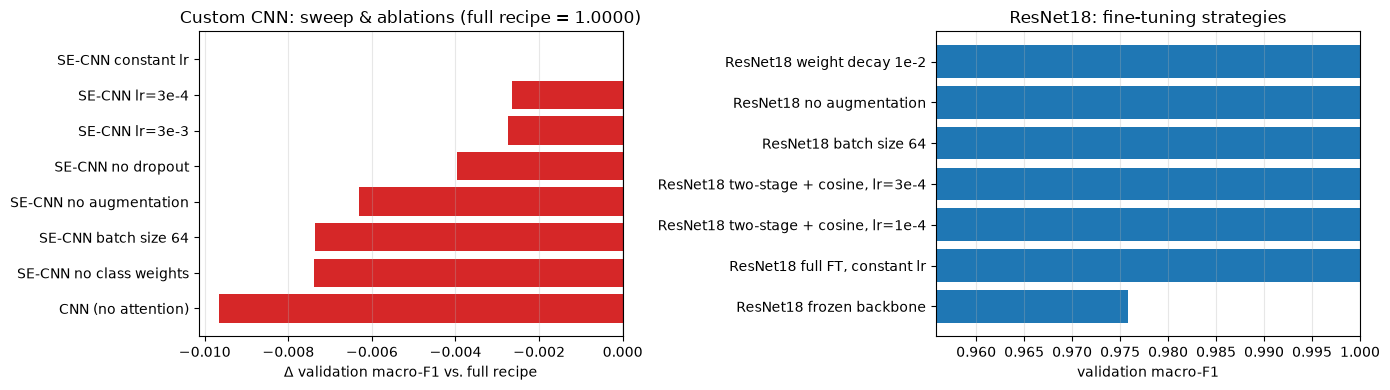

In [7]:
# Ablation chart: change in validation macro-F1 relative to the full CNN recipe
ref = tuning.loc["SE-CNN (full recipe)", "val_macro_f1"]
delta = (tuning.loc[list(cnn_configs)[1:], "val_macro_f1"] - ref).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(
    delta.index,
    delta.values,
    color=["tab:red" if d < 0 else "tab:green" for d in delta.values],
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Δ validation macro-F1 vs. full recipe")
axes[0].set_title(f"Custom CNN: sweep & ablations (full recipe = {ref:.4f})")
ft = tuning.loc[list(resnet_configs), "val_macro_f1"]
axes[1].barh(ft.index, ft.values, color="tab:blue")
axes[1].set_xlim(ft.min() - 0.02, 1.0)
axes[1].set_xlabel("validation macro-F1")
axes[1].set_title("ResNet18: fine-tuning strategies")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
finish("ablations.png")

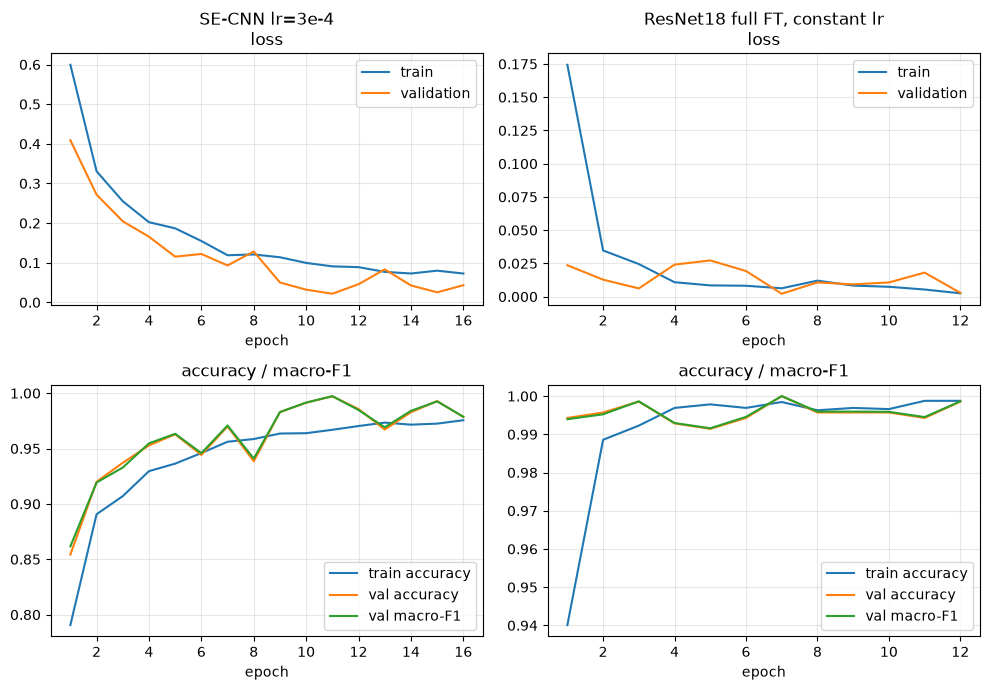

In [8]:
# Learning curves of the selected models (tuning seed)
selected = [
    multi_seed.loc[multi_seed.family == f, "mean over seeds"].idxmax() for f in families
]
fig, axes = plt.subplots(2, len(selected), figsize=(5 * len(selected), 7))
for col, name in enumerate(selected):
    h = histories[name]
    epochs = range(1, len(h["train_loss"]) + 1)
    axes[0, col].plot(epochs, h["train_loss"], label="train")
    axes[0, col].plot(epochs, h["val_loss"], label="validation")
    axes[0, col].set_title(f"{name}\nloss")
    axes[1, col].plot(epochs, h["train_acc"], label="train accuracy")
    axes[1, col].plot(epochs, h["val_acc"], label="val accuracy")
    axes[1, col].plot(epochs, h["val_f1"], label="val macro-F1")
    axes[1, col].set_title("accuracy / macro-F1")
    for ax in axes[:, col]:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
finish("learning_curves.png")